In [ ]:
# install dependencies
# % pip install requests pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# import 
import requests
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime
from IPython.display import display

In [3]:
# api config
API_URL = "https://en.wikipedia.org/w/api.php"

PAGE_TITLE = "Python (programming language)"

HEADERS = {
    "User-Agent": "DigitalArcheologyStudentProject/1.0 (educational research)"
}

print("Target page:", PAGE_TITLE)

Target page: Python (programming language)


In [4]:
# pull revision hisory 
params = {
    "action": "query",
    "format": "json",
    "prop": "revisions",
    "titles": PAGE_TITLE,
    "rvprop": "ids|timestamp|user|comment|size",
    "rvlimit": "500",
    "rvdir": "older"
}

response = requests.get(
    API_URL,
    params=params,
    headers=HEADERS,
    timeout=30
)

response.raise_for_status()
data = response.json()

pages = data["query"]["pages"]
page_data = next(iter(pages.values()))

if "missing" in page_data:
    raise ValueError(f"Wikipedia page not found: {PAGE_TITLE}")

revisions = page_data.get("revisions", [])

print("Page ID:", page_data["pageid"])
print("Page title:", page_data["title"])
print("Revisions retrieved:", len(revisions))

Page ID: 23862
Page title: Python (programming language)
Revisions retrieved: 500


In [5]:
# make a data frame from results
df = pd.DataFrame(revisions)

df = df.rename(columns={
    "revid": "revision_id",
    "parentid": "parent_revision_id",
    "timestamp": "timestamp",
    "user": "username",
    "comment": "edit_comment",
    "size": "article_size_bytes"
})

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

df["edit_comment"] = df["edit_comment"].fillna("")
df["username"] = df["username"].fillna("Unknown")

df["is_anonymous"] = df["username"].str.match(
    r"^\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}$"
)

df["comment_length"] = df["edit_comment"].str.len()

df.head()

,revision_id,parent_revision_id,username,timestamp,article_size_bytes,edit_comment,temp,anon,commenthidden,is_anonymous,comment_length
0,1382144611,1381808176,Comp.arch,2026-10-26 21:56:07+00:00,144917,Three security updates just this month. I.e. t...,NaN,NaN,NaN,False,139
1,1381808176,1381807106,Comp.arch,2026-10-24 22:50:50+00:00,144559,,NaN,NaN,NaN,False,0
2,1381807106,1381806937,Comp.arch,2026-10-24 22:41:39+00:00,144293,/* History */,NaN,NaN,NaN,False,13
3,1381806937,1381613285,Comp.arch,2026-10-24 22:40:12+00:00,144322,"Python 3.15.1 one of frequent ""expedited secur...",NaN,NaN,NaN,False,71
4,1381613285,1381585435,RMCD bot,2026-10-23 17:52:20+00:00,144060,Removing notice of move discussion,NaN,NaN,NaN,False,34


In [6]:
# save to a csv
csv_filename = "wikipedia_python_revisions.csv"

df.to_csv(csv_filename, index=False)

print(f"Saved {len(df)} revisions to {csv_filename}")

Saved 500 revisions to wikipedia_python_revisions.csv


In [7]:
# isnpect data
print("Dataset dimensions:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

print("\nSummary statistics:")
display(df.describe(include="all"))

Dataset dimensions: (500, 11)

Column names:
['revision_id', 'parent_revision_id', 'username', 'timestamp', 'article_size_bytes', 'edit_comment', 'temp', 'anon', 'commenthidden', 'is_anonymous', 'comment_length']

Data types:
revision_id                         int64
parent_revision_id                  int64
username                              str
timestamp             datetime64[us, UTC]
article_size_bytes                  int64
edit_comment                          str
temp                                  str
anon                                  str
commenthidden                         str
is_anonymous                         bool
comment_length                      int64
dtype: object

Missing values:
revision_id             0
parent_revision_id      0
username                0
timestamp               0
article_size_bytes      0
edit_comment            0
temp                  452
anon                  459
commenthidden         499
is_anonymous            0
comment_length       

,revision_id,parent_revision_id,username,timestamp,article_size_bytes,edit_comment,temp,anon,commenthidden,is_anonymous,comment_length
count,5.000000e+02,5.000000e+02,500,500,500.000000,500,48,41,1,500,500.000000
unique,NaN,NaN,249,NaN,NaN,413,1,1,1,2,NaN
top,NaN,NaN,Comp.arch,NaN,NaN,,,,,False,NaN
freq,NaN,NaN,55,NaN,NaN,52,48,41,1,469,NaN
mean,1.333527e+09,1.333351e+09,NaN,2026-01-18 20:54:29.072000+00:00,150859.750000,NaN,NaN,NaN,NaN,NaN,74.314000
min,1.293863e+09,1.293863e+09,NaN,2025-06-04 02:59:00+00:00,125129.000000,NaN,NaN,NaN,NaN,NaN,0.000000
25%,1.311089e+09,1.310976e+09,NaN,2025-09-13 09:20:43.250000+00:00,140414.750000,NaN,NaN,NaN,NaN,NaN,16.000000
50%,1.325176e+09,1.324516e+09,NaN,2025-12-01 15:02:11+00:00,143654.000000,NaN,NaN,NaN,NaN,NaN,44.000000
75%,1.358266e+09,1.358208e+09,NaN,2026-06-07 17:08:36+00:00,166960.000000,NaN,NaN,NaN,NaN,NaN,119.000000
max,1.382145e+09,1.381808e+09,NaN,2026-10-26 21:56:07+00:00,179854.000000,NaN,NaN,NaN,NaN,NaN,500.000000


C:\Users\Jackson\AppData\Local\Temp\ipykernel_31968\114583919.py:2: UserWarning: Converting to PeriodArray/Index representation will drop timezone information.
  df["month"] = df["timestamp"].dt.to_period("M").astype(str)


,month,revision_count
0,2025-06,15
1,2025-07,38
2,2025-08,57
3,2025-09,38
4,2025-10,64
5,2025-11,37
6,2025-12,19
7,2026-01,12
8,2026-02,18
9,2026-03,19


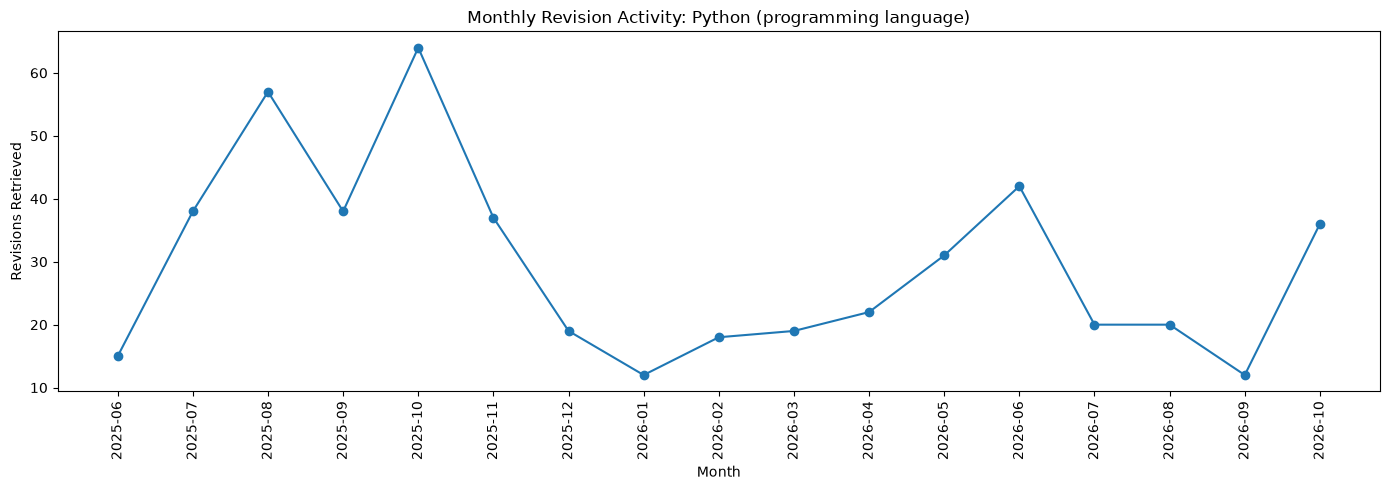

In [8]:
# early anlysis
df["month"] = df["timestamp"].dt.to_period("M").astype(str)

monthly_edits = (
    df.groupby("month")
    .size()
    .reset_index(name="revision_count")
    .sort_values("month")
)

display(monthly_edits.head(10))

plt.figure(figsize=(14, 5))
plt.plot(
    monthly_edits["month"],
    monthly_edits["revision_count"],
    marker="o"
)

plt.title(f"Monthly Revision Activity: {PAGE_TITLE}")
plt.xlabel("Month")
plt.ylabel("Revisions Retrieved")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [9]:
# find most active
editor_counts = (
    df.groupby("username")
    .agg(
        revision_count=("revision_id", "count"),
        anonymous=("is_anonymous", "max")
    )
    .sort_values("revision_count", ascending=False)
    .head(10)
)

display(editor_counts)

,revision_count,anonymous
username,,
Comp.arch,55,False
W.andrea,37,False
Gadfium,18,False
Lokiretro,13,False
ClueBot NG,10,False
AnomieBOT,9,False
Panamitsu,8,False
Hooman Mallahzadeh,7,False
Graywalls,7,False


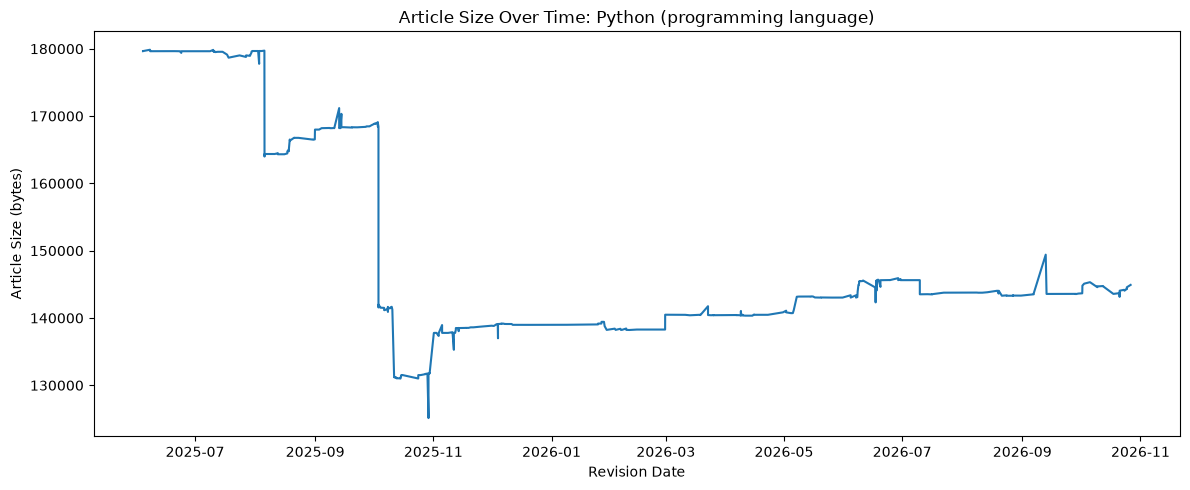

In [10]:
# examine size changes
df_sorted = df.sort_values("timestamp")

plt.figure(figsize=(12, 5))
plt.plot(
    df_sorted["timestamp"],
    df_sorted["article_size_bytes"]
)

plt.title(f"Article Size Over Time: {PAGE_TITLE}")
plt.xlabel("Revision Date")
plt.ylabel("Article Size (bytes)")
plt.tight_layout()
plt.show()

In [11]:
# examine comments
print("Percentage of revisions with a nonempty comment:",
      round((df["edit_comment"].str.strip() != "").mean() * 100, 2), "%")

print("\nMost recent 15 revisions:")

display(
    df.sort_values("timestamp", ascending=False)[
        ["timestamp", "username", "article_size_bytes", "edit_comment"]
    ].head(15)
)

Percentage of revisions with a nonempty comment: 89.6 %

Most recent 15 revisions:


,timestamp,username,article_size_bytes,edit_comment
0,2026-10-26 21:56:07+00:00,Comp.arch,144917,Three security updates just this month. I.e. t...
1,2026-10-24 22:50:50+00:00,Comp.arch,144559,
2,2026-10-24 22:41:39+00:00,Comp.arch,144293,/* History */
3,2026-10-24 22:40:12+00:00,Comp.arch,144322,"Python 3.15.1 one of frequent ""expedited secur..."
4,2026-10-23 17:52:20+00:00,RMCD bot,144060,Removing notice of move discussion
5,2026-10-23 14:16:21+00:00,RMCD bot,144186,Notifying subject page of move discussion on [...
6,2026-10-21 06:28:29+00:00,T8y,144060,Correct dictionary key requirements: hashabili...
7,2026-10-21 05:35:21+00:00,T8y,143681,Revert misleading citation introduced in [[Spe...
8,2026-10-21 05:23:54+00:00,T8y,143138,Revert revision [[Special:Diff/1381269714]]: I...
9,2026-10-21 05:10:28+00:00,~2026-56033-10,143243,added source for new python council members
